    b   analytic  SM single  astrosticks  raw Watson (g||z)
  0.0    1.00000    1.00000      1.00000 
  0.5    0.74682    0.74680      0.74682 
  1.0    0.59814    0.59810      0.59814 
  1.5    0.50434    0.50427      0.50434 
  2.0    0.44104    0.44095      0.44104 
  2.5    0.39571    0.39560      0.39571 
  3.0    0.36161    0.36148      0.36161 
  3.5    0.33490    0.33476      0.33490 
  4.0    0.31331    0.31315      0.31331 
  4.5    0.29540    0.29524      0.29540 
  5.0    0.28025    0.28007      0.28025 
  5.5    0.26721    0.26702      0.26721 
  6.0    0.25583    0.25563      0.25583 
  6.5    0.24580    0.24559      0.24580 
  7.0    0.23685    0.23664      0.23685 
  7.5    0.22882    0.22860      0.22882 
  8.0    0.22156    0.22133      0.22156 
  8.5    0.21494    0.21471      0.21494 
  9.0    0.20889    0.20865      0.20889 
  9.5    0.20331    0.20308      0.20331 
 10.0    0.19817    0.19792      0.19817 

max |SM single  - analytic| = 0.00024176420060950665
max 

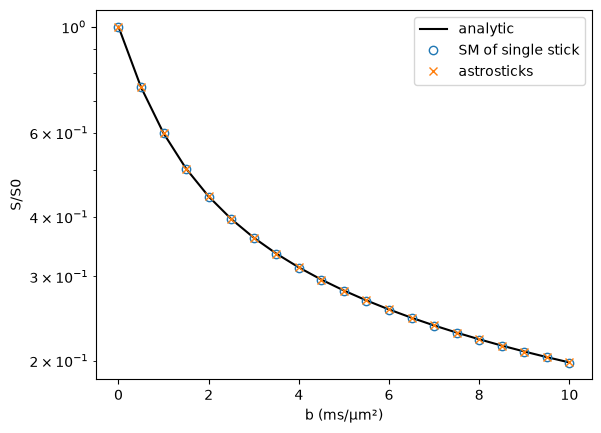

In [3]:
import numpy as np
from scipy.special import erf

def fibonacci_sphere(n):
    """Approximately uniform points on the unit sphere."""
    i = np.arange(n) + 0.5
    phi = np.arccos(1 - 2 * i / n)
    theta = np.pi * (1 + 5 ** 0.5) * i
    return np.stack([np.cos(theta) * np.sin(phi),
                     np.sin(theta) * np.sin(phi),
                     np.cos(phi)], axis=1)

def stick_signal(b, D, g, n):
    """S = exp(-b D (g.n)^2). g: (N,3) or (3,), n: (M,3) or (3,)."""
    dot = np.atleast_2d(g) @ np.atleast_2d(n).T       # (N, M)
    return np.exp(-b * D * dot**2)

def analytic(b, D):
    """(sqrt(pi)/2) * erf(sqrt(bD)) / sqrt(bD), with limit 1 at b=0."""
    x = np.sqrt(b * D)
    out = np.ones_like(x)
    nz = x > 0
    out[nz] = np.sqrt(np.pi) / 2 * erf(x[nz]) / x[nz]
    return out

# --- settings ---
D = 2.0                                  # um^2/ms (D_parallel)
bvals = np.linspace(0, 10, 21)           # ms/um^2  (= 0..10,000 s/mm^2)
dirs = fibonacci_sphere(500)             # gradient directions (for spherical mean)
orients = fibonacci_sphere(5000)         # stick orientations (for astrosticks)

# 1) Spherical mean of ONE stick (arbitrary orientation n), averaged over g
n0 = np.array([1.0, 2.0, -0.5]); n0 /= np.linalg.norm(n0)
sm_single = np.array([stick_signal(b, D, dirs, n0).mean() for b in bvals])

# 2) Astrosticks: fixed g, uniform average over stick orientations n
g0 = np.array([0.0, 0.0, 1.0])
astro = np.array([stick_signal(b, D, g0, orients).mean() for b in bvals])

# 3) Spherical mean of a *coherent* bundle with a Watson-like ODF.
#    Weighted stick population, still averaged over g -> should be identical.
kappa, mu = 20.0, np.array([0.0, 0.0, 1.0])
w = np.exp(kappa * (orients @ mu) ** 2); w /= w.sum()
sm_watson = np.array([(stick_signal(b, D, dirs, orients) @ w).mean()
                      for b in bvals])



ref = analytic(bvals, D)

print(f"{'b':>5} {'analytic':>10} {'SM single':>10} {'astrosticks':>12} "
      f"{'raw Watson (g||z)':>18}")
for i, b in enumerate(bvals):
    print(f"{b:5.1f} {ref[i]:10.5f} {sm_single[i]:10.5f} {astro[i]:12.5f} "
          )

print("\nmax |SM single  - analytic| =", np.abs(sm_single - ref).max())
print("max |astrosticks - analytic| =", np.abs(astro - ref).max())


# Optional plot
try:
    import matplotlib.pyplot as plt
    plt.plot(bvals, ref, 'k-', label='analytic')
    plt.plot(bvals, sm_single, 'o', mfc='none', label='SM of single stick')
    plt.plot(bvals, astro, 'x', label='astrosticks')

    plt.xlabel('b (ms/µm²)'); plt.ylabel('S/S0'); plt.yscale('log')
    plt.legend(); plt.show()
except ImportError:
    pass